# SEM basics · 7 — a 3-D model

In 3-D `PropSEM` takes the same constructor and call with one more axis:
`shape=(nz, ny, nx)`, positions `[ix, iy, iz]`, and a topography of shape `(ny, nx)`.
This notebook runs:

1. **Acoustic** — `AcousticSEM3D` on a two-layer model, a 2-D receiver grid on the surface
2. **Elastic** — `ElasticVSSEM3D`, three-component records
3. **Topography** — `AcousticSEM3DDeformed` under a 3-D hill
4. **A gradient** — one `.backward()` in 3-D

All three equations have CUDA kernels (`impl='c'`); on the CPU they run eager,
much more slowly. About a minute on a GPU.

In [1]:
import time
import numpy as np
import torch
import matplotlib.pyplot as plt

from sweep.sem import PropSEM
from sweep.sem.equations import AcousticSEM3D, AcousticSEM3DDeformed, ElasticVSSEM3D
from sweep.signal import ricker

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('device:', device)

dh, n_order = 10.0, 4
shape = (41, 61, 61)              # (nz, ny, nx): 400 m deep, 600 m x 600 m
nz, ny, nx = shape
dt, nt = 0.6e-3, 1000

device: cuda


## 1. Acoustic

A free surface on top and the C-PML on the five other sides (`abcn` cells, as in
2-D). The source is in the middle, 20 m deep; the receivers fill the surface every
20 m, so `receivers` has shape `(1, nrec, 3)` with columns `[ix, iy, iz]`.

In [2]:
f0 = 10.0
wavelet = ricker(np.arange(nt) * dt - 1.2 / f0, f=f0).astype(np.float32)
vp = torch.full(shape, 1500.0, device=device)
vp[20:] = 2500.0                                   # interface at 200 m

src = np.array([[nx // 2, ny // 2, 2]])            # [ix, iy, iz]
iy, ix = np.meshgrid(np.arange(0, ny, 2), np.arange(0, nx, 2), indexing='ij')
receivers = np.stack([ix.ravel(), iy.ravel(), np.full(ix.size, 2)], axis=1)[None]
print('sources', src.shape, ' receivers', receivers.shape)

solver = PropSEM(AcousticSEM3D, shape=shape, dh=dh, dt=dt, n_order=n_order,
                 abcn=20, free_surface=True, f_dominant=f0, device=device)
m = solver.mesh
print('impl', solver.impl, '| mesh', type(m).__name__, m.n_elements, 'elements,',
      m.n_global, 'GLL nodes')
t0 = time.perf_counter()
with torch.no_grad():
    seis = solver(wavelet, src, receivers, models=[vp])
if device == 'cuda':
    torch.cuda.synchronize()
print('record', tuple(seis.shape), f' {time.perf_counter() - t0:.2f} s')

sources (1, 3)  receivers (1, 961, 3)


impl c | mesh Hex8Mesh 9375 elements, 622261 GLL nodes


record (1, 1000, 961, 1)  0.63 s


The record is `(nshots, nt, nrec, 1)` as in 2-D. Reshaped to the receiver grid it
gives the surface wavefield at any time (a time slice), and one row of it a
2-D gather:

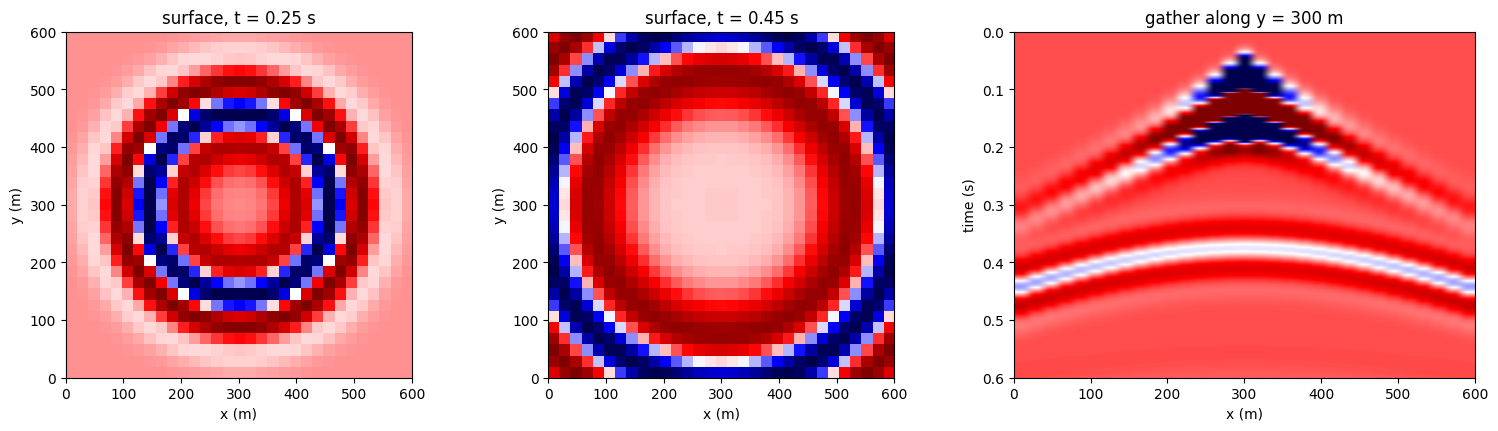

In [3]:
rec = seis[0, :, :, 0].cpu().numpy().reshape(nt, *ix.shape)      # (nt, ny', nx')
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), constrained_layout=True)
for ax, ts in zip(axes[:2], (0.25, 0.45)):
    sl = rec[int(round(ts / dt))]
    lo, hi = np.percentile(sl[sl != 0], [1, 99])
    ax.imshow(sl, cmap='seismic', vmin=lo, vmax=hi, origin='lower',
              extent=[0, (nx - 1) * dh, 0, (ny - 1) * dh])
    ax.set_title(f'surface, t = {ts:.2f} s'); ax.set_xlabel('x (m)'); ax.set_ylabel('y (m)')
g = rec[:, ix.shape[0] // 2, :]
lo, hi = np.percentile(g[g != 0], [2, 98])
axes[2].imshow(g, cmap='seismic', vmin=lo, vmax=hi, aspect='auto',
               extent=[0, (nx - 1) * dh, nt * dt, 0])
axes[2].set_title('gather along y = 300 m'); axes[2].set_xlabel('x (m)')
axes[2].set_ylabel('time (s)')
plt.show()

The time slices show the direct wave as a ring and, at 0.45 s, the reflection
from the interface behind it; the gather shows the same two and their
free-surface multiple.

## 2. Elastic

`ElasticVSSEM3D` takes `[vp, vs, rho]` and records `vx`, `vy`, `vz`. The default
source is a vertical force (`source_type=['vz']`; `['vx']` and `['vy']` are the
horizontal forces). One line of receivers along x:

impl c  record (1, 1000, 61, 3)  0.56 s


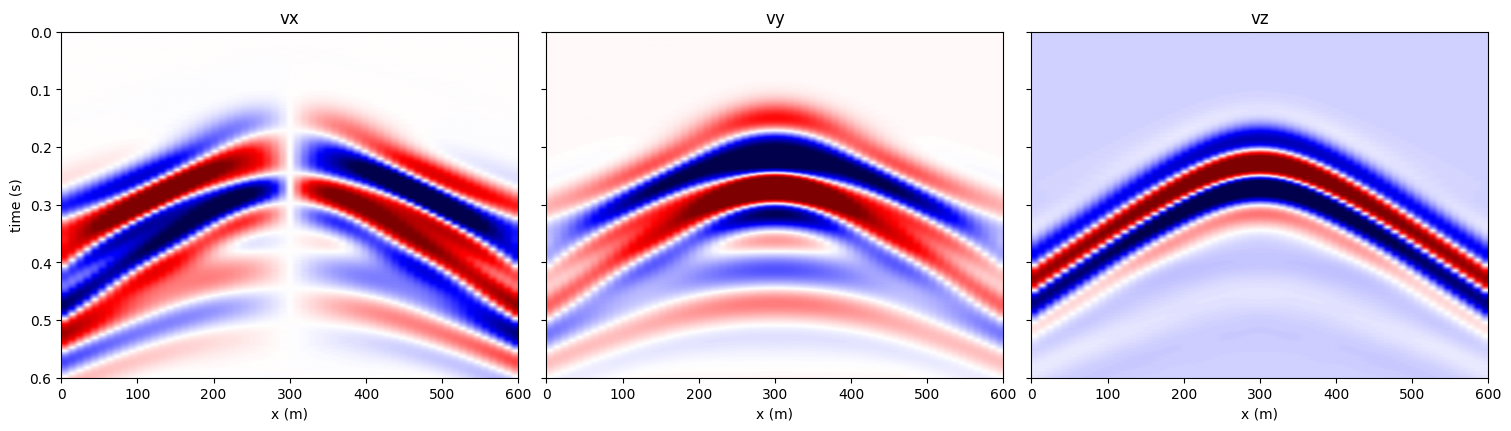

In [4]:
f0 = 8.0
wavelet = ricker(np.arange(nt) * dt - 1.2 / f0, f=f0).astype(np.float32)
vp  = torch.full(shape, 2000.0, device=device); vp[20:]  = 2800.0
vs  = torch.full(shape, 1200.0, device=device); vs[20:]  = 1600.0
rho = torch.full(shape, 2000.0, device=device); rho[20:] = 2200.0

rx = np.arange(0, nx)
line = np.stack([rx, np.full_like(rx, ny // 2 + 10), np.full_like(rx, 2)], axis=1)[None]
solver_el = PropSEM(ElasticVSSEM3D, shape=shape, dh=dh, dt=dt, n_order=n_order,
                    abcn=20, free_surface=True, f_dominant=f0,
                    receiver_type=['vx', 'vy', 'vz'], device=device)
t0 = time.perf_counter()
with torch.no_grad():
    seis_el = solver_el(wavelet, src, line, models=[vp, vs, rho])
if device == 'cuda':
    torch.cuda.synchronize()
print('impl', solver_el.impl, ' record', tuple(seis_el.shape),
      f' {time.perf_counter() - t0:.2f} s')

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), sharey=True, constrained_layout=True)
for c, (ax, name) in enumerate(zip(axes, ['vx', 'vy', 'vz'])):
    g = seis_el[0, :, :, c].cpu().numpy()
    lo, hi = np.percentile(g[g != 0], [2, 98])
    ax.imshow(g, cmap='seismic', vmin=lo, vmax=hi, aspect='auto',
              extent=[0, (nx - 1) * dh, nt * dt, 0])
    ax.set_title(name); ax.set_xlabel('x (m)')
axes[0].set_ylabel('time (s)')
plt.show()

The line runs 100 m off the source in y, so all three components move: `vz` is
dominated by the surface wave, `vx` changes sign where the line passes the
source, and `vy` is the motion across the line.

## 3. Topography

`topography` is the surface row at every `(iy, ix)`, shape `(ny, nx)`, fractional
allowed; it needs a deformable (`hex27`) equation such as `AcousticSEM3DDeformed`.
A 100 m hill in the middle, the source under its crest:

impl c  mesh Hex27Mesh  record (1, 1000, 59, 1)


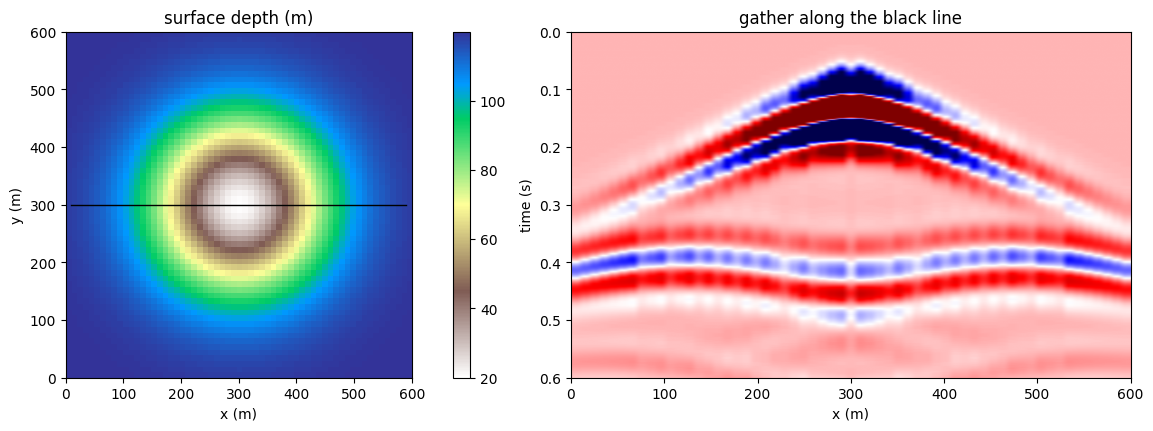

In [5]:
f0 = 10.0
wavelet = ricker(np.arange(nt) * dt - 1.2 / f0, f=f0).astype(np.float32)
yy, xx = np.meshgrid(np.arange(ny), np.arange(nx), indexing='ij')
topo = 12.0 - 10.0 * np.exp(-((xx - nx // 2) ** 2 + (yy - ny // 2) ** 2) / 15.0 ** 2)
vp = torch.full(shape, 1500.0, device=device); vp[25:] = 2500.0

solver_t = PropSEM(AcousticSEM3DDeformed, shape=shape, dh=dh, dt=dt, n_order=n_order,
                   abcn=20, topography=topo, f_dominant=f0, device=device)
src_t = np.array([[nx // 2, ny // 2, 6]])                  # 40 m below the crest
rx = np.arange(1, nx - 1)                                  # inside the model edges
line_t = np.stack([rx, np.full_like(rx, ny // 2), np.ceil(topo[ny // 2, rx]) + 1],
                  axis=1)[None]                            # just below the surface
with torch.no_grad():
    seis_t = solver_t(wavelet, src_t, line_t, models=[vp])
print('impl', solver_t.impl, ' mesh', type(solver_t.mesh).__name__, ' record', tuple(seis_t.shape))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), constrained_layout=True)
im = axes[0].imshow(topo * dh, cmap='terrain_r', origin='lower',
                    extent=[0, (nx - 1) * dh, 0, (ny - 1) * dh])
axes[0].plot(rx * dh, np.full_like(rx, ny // 2) * dh, 'k-', lw=1)
axes[0].set_title('surface depth (m)'); axes[0].set_xlabel('x (m)'); axes[0].set_ylabel('y (m)')
fig.colorbar(im, ax=axes[0])
g = seis_t[0, :, :, 0].cpu().numpy()
lo, hi = np.percentile(g[g != 0], [2, 98])
axes[1].imshow(g, cmap='seismic', vmin=lo, vmax=hi, aspect='auto',
               extent=[0, (nx - 1) * dh, nt * dt, 0])
axes[1].set_title('gather along the black line'); axes[1].set_xlabel('x (m)')
axes[1].set_ylabel('time (s)')
plt.show()

## 4. A gradient

The 3-D call is differentiable like the 2-D one. One shot, a homogeneous initial
model against the two-layer data of section 1; the gradient comes back on the
`(nz, ny, nx)` grid. On `impl='c'` the default memory strategy is boundary
saving (`solver.memory_strategy` says so), which matters most in 3-D, where a
full forward history grows as `nz x ny x nx x nt`; see *SEM basics · 5* for the
options.

memory strategy boundary  loss 3.066e+04  grad (41, 61, 61)


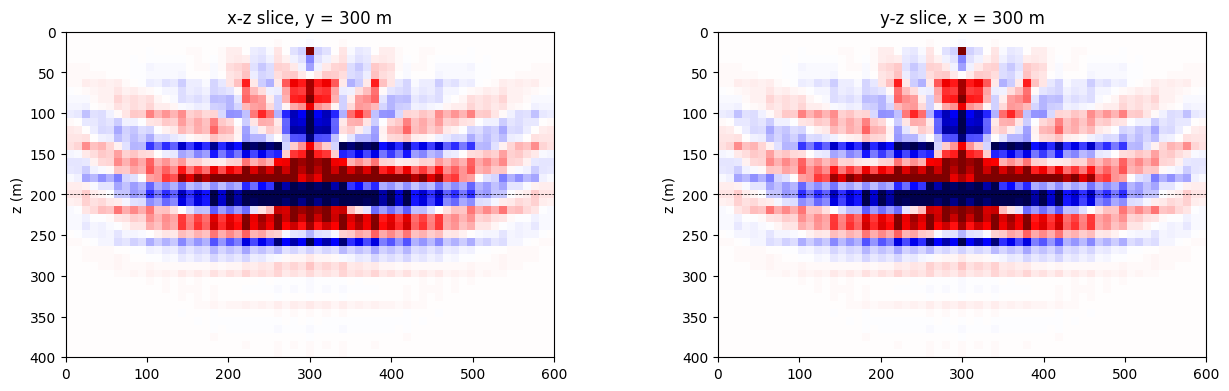

In [6]:
vp_true = torch.full(shape, 1500.0, device=device); vp_true[20:] = 2500.0
with torch.no_grad():
    obs = solver(wavelet, src, receivers, models=[vp_true])
scale = 1.0 / float(obs.pow(2).mean().sqrt())               # O(1) data, see notebook 5

vp0 = torch.full(shape, 1500.0, device=device, requires_grad=True)
pred = solver(wavelet * scale, src, receivers, models=[vp0])
loss = 0.5 * (pred - obs * scale).pow(2).sum()
loss.backward()
print('memory strategy', solver.memory_strategy, ' loss %.3e' % loss.item(),
      ' grad', tuple(vp0.grad.shape))

g = vp0.grad.cpu().numpy()
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), constrained_layout=True)
for ax, img, title, ext in [
        (axes[0], g[:, ny // 2, :], 'x-z slice, y = 300 m', [0, (nx - 1) * dh, (nz - 1) * dh, 0]),
        (axes[1], g[:, :, nx // 2], 'y-z slice, x = 300 m', [0, (ny - 1) * dh, (nz - 1) * dh, 0])]:
    lo, hi = np.percentile(img[6:][img[6:] != 0], [2, 98])
    ax.imshow(img, cmap='seismic', vmin=lo, vmax=hi, extent=ext)
    ax.axhline(200, color='k', lw=0.5, ls='--')
    ax.set_title(title); ax.set_ylabel('z (m)')
plt.show()

The gradient is strongest along the interface at 200 m (dashed), where the
initial model is missing the velocity increase, and along the wavepaths from the
source down to it; the two slices are the same, as the problem is symmetric in x
and y around the source.

## Summary

| | 2-D | 3-D |
| --- | --- | --- |
| `shape` | `(nz, nx)` | `(nz, ny, nx)` |
| positions | `[ix, iz]` | `[ix, iy, iz]` |
| `topography` | `(nx,)` | `(ny, nx)` |
| edges for `free_surface` | top, bottom, left, right | adds front, back |
| `impl='c'` equations | `AcousticPotentialSEM2D`, `ElasticSEM2DDeformed`, `AcousticElasticSEM2D` | `AcousticSEM3D`, `AcousticSEM3DDeformed`, `ElasticVSSEM3D` |

Larger 3-D models run across several GPUs with `sweep.sem.dd`; see the
[SEM user guide](../../user-guide/sem/).

Next: [SEM basics · 8 — anisotropic and poroelastic rocks](../57_sem_vti_and_biot/).

---

<p><strong>Download this notebook</strong> &mdash; <a href="56_sem_3d.ipynb" download><code>56_sem_3d.ipynb</code></a> &middot; or <a href="https://github.com/DeepWave-KAUST/sweep/blob/dev/docs/notebooks/56_sem_3d.ipynb">view on GitHub</a></p>